## 02 — Clean Text & Normalize Dataset

**Mục tiêu**: làm sạch dữ liệu tuyển dụng (text + salary) cho bài toán phân cụm việc làm.

**Input** (đã được split ở `01_split_and_export.ipynb`):
- `data/raw/raw_data_train.csv`
- `data/raw/raw_data_test.csv`

**Output**:
- `data/clean/clean_data_train.csv`
- `data/clean/clean_data_test.csv`

---

**Cấu trúc**:
1. Setup
2. Helper functions: `parse_salary()`, `clean_text()`
3. Pipeline function: `clean_pipeline(df)` — gom toàn bộ các bước cleaning
4. **Cell clean train** — load `raw_data_train.csv` → pipeline → save `clean_data_train.csv`
5. **Cell clean test** — load `raw_data_test.csv` → pipeline → save `clean_data_test.csv`
6. Sanity check

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import re
import urllib.request
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 100)

# Input — đọc parquet (nhanh hơn CSV ~5-10x)
RAW_TRAIN_PATH = Path('../data/raw/raw_data_train.parquet')
RAW_TEST_PATH  = Path('../data/raw/raw_data_test.parquet')

# Output — xuất CSV (cho submission) + parquet (cho pipeline downstream)
OUT_TRAIN_CSV     = Path('../data/clean/clean_data_train.csv')
OUT_TEST_CSV      = Path('../data/clean/clean_data_test.csv')
OUT_TRAIN_PARQUET = Path('../data/clean/clean_data_train.parquet')
OUT_TEST_PARQUET  = Path('../data/clean/clean_data_test.parquet')
OUT_TRAIN_CSV.parent.mkdir(parents=True, exist_ok=True)

## 2. Helper functions

### 2.1 `parse_salary()` — parse chuỗi salary → `(min, max, status)` triệu VND

Định dạng salary trong dataset rất đa dạng (VND, USD, "triệu", "thỏa thuận", "0 VND"…). Hàm này:
1. Phát hiện `negotiable` (thỏa thuận / cập nhật / cạnh tranh) → status `negotiable`, min/max = NaN.
2. Phát hiện USD → quy đổi × 25,000 VND.
3. Bỏ dấu chấm hàng nghìn (`10.000.000` → `10000000`), trích số bằng regex.
4. Quy đổi về **triệu VND** (chia 10⁶ nếu là VND nguyên).
5. Validate ngưỡng: drop nếu < 0.3 triệu (`outlier_low`) hoặc > 500 triệu (`outlier_high`).

In [2]:
USD_TO_VND = 25_000
NEGOTIABLE_KEYWORDS = [
    'thỏa thuận', 'thoả thuận', 'thương lượng', 'cạnh tranh',
    'đang cập nhật', 'chưa cập nhật', 'negotiable',
]
MAX_SALARY_MILLION = 500
MIN_SALARY_MILLION = 0.3

def parse_salary(s):
    """Parse salary string → (min, max, status) in million VND."""
    if pd.isna(s):
        return (np.nan, np.nan, 'null')
    s = str(s).strip().lower()
    if not s:
        return (np.nan, np.nan, 'null')
    if any(kw in s for kw in NEGOTIABLE_KEYWORDS):
        return (np.nan, np.nan, 'negotiable')

    is_usd = ('usd' in s) or ('$' in s)
    s_clean = re.sub(r'[^\d\.\-\s]', ' ', s).strip()
    s_clean = re.sub(r'(?<=\d)\.(?=\d{3})', '', s_clean)
    nums = [float(x) for x in re.findall(r'\d+\.?\d*', s_clean) if x]
    if not nums:
        return (np.nan, np.nan, 'no_number')

    if len(nums) >= 2:
        lo, hi = nums[0], nums[1]
    else:
        lo, hi = nums[0], nums[0]

    if is_usd:
        lo = lo * USD_TO_VND / 1_000_000
        hi = hi * USD_TO_VND / 1_000_000
    elif lo >= 1_000_000:
        lo, hi = lo / 1_000_000, hi / 1_000_000

    if lo <= 0 or hi <= 0:
        return (np.nan, np.nan, 'zero')
    if lo > MAX_SALARY_MILLION or hi > MAX_SALARY_MILLION:
        return (np.nan, np.nan, 'outlier_high')
    if lo < MIN_SALARY_MILLION:
        return (np.nan, np.nan, 'outlier_low')
    if lo > hi:
        lo, hi = hi, lo
    return (lo, hi, 'ok')

# Unit test
_tests = [
    ('10.000.000 - 15.000.000 VND',  'ok'),
    ('15 - 25 triệu',                'ok'),
    ('4000 usd',                     'ok'),
    ('Thỏa thuận',                   'negotiable'),
    ('0 VND',                        'zero'),
    (None,                           'null'),
]
for inp, expected in _tests:
    _, _, status = parse_salary(inp)
    assert status == expected, f'parse_salary({inp!r}) → {status}, expected {expected}'
print('✓ parse_salary unit tests passed')

✓ parse_salary unit tests passed


### 2.2 Stopwords + `clean_text()`

- **VI**: 645 stopwords tiếng Việt từ `stopwords-iso/stopwords-vi`.
- **EN**: 318 English stopwords từ `sklearn.feature_extraction.text.ENGLISH_STOP_WORDS` (lọc JD tiếng Anh).
- **DOMAIN**: tạm bỏ trống. Sau bước cleaning, mục 7 sẽ tokenize bằng pyvi và vẽ biểu đồ top term frequency → **data-driven** xác định domain stopwords thay vì hand-picked.

`clean_text()` lowercase, bỏ HTML / URL / email / phone / ký tự đặc biệt, normalize whitespace, loại stopwords.

In [3]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

_url = 'https://raw.githubusercontent.com/stopwords-iso/stopwords-vi/master/stopwords-vi.txt'
with urllib.request.urlopen(_url) as r:
    VI_STOPWORDS = set(r.read().decode('utf-8').splitlines())

EN_STOPWORDS = set(ENGLISH_STOP_WORDS)

DOMAIN_STOPWORDS = set()

STOPWORDS = frozenset(VI_STOPWORDS | EN_STOPWORDS | DOMAIN_STOPWORDS)
print(f'Loaded {len(STOPWORDS):,} stopwords ({len(VI_STOPWORDS)} VI + {len(EN_STOPWORDS)} EN + {len(DOMAIN_STOPWORDS)} domain)')

Loaded 960 stopwords (645 VI + 318 EN + 0 domain)


In [4]:
def clean_text(text, _sw=STOPWORDS):
    """Normalize text: lowercase, strip HTML/URL/email/phone, remove stopwords."""
    if pd.isna(text):
        return ''
    text = str(text).lower()
    text = re.sub(r'<.*?>', ' ', text)                  # HTML
    text = re.sub(r'http\S+|www\S+', ' ', text)         # URL
    text = re.sub(r'\S+@\S+', ' ', text)                # email
    text = re.sub(r'\b\d{9,11}\b', ' ', text)           # phone
    text = re.sub(r'[^a-zA-ZÀ-ỹ0-9\s]', ' ', text)      # special chars (giữ tiếng Việt)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = [t for t in text.split() if t not in _sw]
    return ' '.join(tokens)

## 3. Pipeline function `clean_pipeline(df)`

Gom toàn bộ các bước cleaning vào 1 hàm để train và test cùng đi qua **đúng cùng pipeline**. Thứ tự:

| Bước | Mô tả | Cột bị thay đổi |
|---|---|---|
| 1 | Apply `parse_salary` → tạo `salary_min`, `salary_max`, `parse_status` | + 3 cột mới |
| 2 | Drop dòng có status xấu (`outlier_high/low`, `zero`, `no_number`, `null`); giữ `negotiable` | drop rows |
| 3 | Apply `clean_text` lên 5 cột text | `job_title`, `job_description`, `requirements`, `benefits`, `company_name` |
| 4 | Drop duplicate (toàn dòng + theo `job_title` + `job_description`) | drop rows |
| 5 | Tính `desc_len`, drop JD < 20 tokens | + 1 cột, drop rows |
| 6 | Tạo `combined_text` = `title × 2 + description + requirements` (title nhân đôi vì quan trọng) + `combined_len` | + 2 cột |

In counts ở mỗi bước để dễ debug.

In [5]:
TEXT_COLUMNS = ['job_title', 'job_description', 'requirements', 'benefits', 'company_name']
DROP_STATUSES = ['outlier_high', 'outlier_low', 'zero', 'no_number', 'null']
MIN_DESC_TOKENS = 20

def clean_pipeline(df, name=''):
    """Run full cleaning pipeline on a DataFrame. Return cleaned df."""
    print(f'=== Cleaning {name} ===')
    n0 = len(df)
    print(f'Input: {n0:,} rows × {df.shape[1]} cols')

    # 1. parse_salary
    parsed = df['salary'].apply(parse_salary)
    df = df.assign(
        salary_min=parsed.apply(lambda x: x[0]),
        salary_max=parsed.apply(lambda x: x[1]),
        parse_status=parsed.apply(lambda x: x[2]),
    )
    # salary_normalized = midpoint của range (triệu VND); NaN cho negotiable
    # FE downstream sẽ thay 0/NaN bằng median theo job_position
    df['salary_normalized'] = df[['salary_min', 'salary_max']].mean(axis=1).fillna(0)
    ok_pct = (df['parse_status'] == 'ok').mean() * 100
    print(f'  [1] parse_salary: {ok_pct:.2f}% ok  (salary_normalized = mean(min, max))')

    # 2. drop salary outliers
    before = len(df)
    df = df[~df['parse_status'].isin(DROP_STATUSES)].copy()
    print(f'  [2] drop salary outliers: -{before - len(df):,} rows → {len(df):,}')

    # 3. clean_text
    existing_text_cols = [c for c in TEXT_COLUMNS if c in df.columns]
    for col in existing_text_cols:
        df[col] = df[col].fillna('').apply(clean_text)
    print(f'  [3] clean_text: {len(existing_text_cols)} cols normalized')

    # 4. drop duplicates
    before = len(df)
    df = df.drop_duplicates()
    df = df.drop_duplicates(subset=['job_title', 'job_description'])
    print(f'  [4] drop duplicates: -{before - len(df):,} rows → {len(df):,}')

    # 5. drop short descriptions
    df['desc_len'] = df['job_description'].fillna('').str.split().str.len()
    before = len(df)
    df = df[df['desc_len'] >= MIN_DESC_TOKENS].copy()
    print(f'  [5] drop desc < {MIN_DESC_TOKENS} tokens: -{before - len(df):,} rows → {len(df):,}')

    # 6. create combined_text
    df['combined_text'] = (
        df['job_title'].fillna('') + ' ' +
        df['job_title'].fillna('') + ' ' +     # nhân đôi title vì quan trọng nhất
        df['job_description'].fillna('') + ' ' +
        df['requirements'].fillna('')
    )
    df['combined_len'] = df['combined_text'].str.split().str.len()
    print(f'  [6] combined_text created')

    print(f'Output: {len(df):,} rows × {df.shape[1]} cols  (kept {len(df)/n0*100:.2f}% of input)')
    return df

### 3.1 Helper: trực quan hóa `parse_status` trước vs sau khi drop

Vẽ count của từng `parse_status` ở 2 thời điểm để xác nhận đã drop đúng các nhóm outlier (`outlier_high`, `outlier_low`, `zero`, `no_number`, `null`) và giữ lại `ok` + `negotiable`. Dùng seaborn palette `Set2`.

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_parse_status(before_df, after_df, title=''):
    """Vẽ count của parse_status trước vs sau khi drop. Dùng seaborn palette='Set2'."""
    before_counts = before_df['parse_status'].value_counts().sort_index()
    after_counts  = after_df['parse_status'].value_counts().sort_index()

    all_statuses  = sorted(set(before_counts.index) | set(after_counts.index))
    before_counts = before_counts.reindex(all_statuses, fill_value=0)
    after_counts  = after_counts.reindex(all_statuses,  fill_value=0)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    palette = sns.color_palette('Set2', n_colors=len(all_statuses))

    for ax, counts, label in [(axes[0], before_counts, 'BEFORE drop'),
                               (axes[1], after_counts,  'AFTER drop')]:
        sns.barplot(x=list(counts.index), y=counts.values,
                    ax=ax, palette=palette, hue=list(counts.index),
                    legend=False)
        ax.set_title(f'{title} — {label}', fontsize=12, fontweight='bold')
        ax.set_xlabel('parse_status'); ax.set_ylabel('Count')
        ax.tick_params(axis='x', rotation=45)
        for i, v in enumerate(counts.values):
            ax.text(i, v, f'{int(v):,}', ha='center', va='bottom', fontsize=9)

    plt.tight_layout(); plt.show()


def compute_parse_status(raw_df):
    """Tính parse_status cho raw df (chưa qua pipeline) — dùng để lấy 'before' state."""
    return raw_df.assign(
        parse_status=raw_df['salary'].apply(lambda s: parse_salary(s)[2])
    )

## 4. Clean train data

Load `raw_data_train.csv` → `clean_pipeline()` → save `clean_data_train.csv`.

In [7]:
%%time
train_raw = pd.read_parquet(RAW_TRAIN_PATH)
train_clean = clean_pipeline(train_raw, name='TRAIN')
print(f'\n✓ Cleaned TRAIN (in-memory): {train_clean.shape} — chưa save, đợi apply DOMAIN_STOPWORDS')

=== Cleaning TRAIN ===
Input: 546,190 rows × 14 cols
  [1] parse_salary: 96.71% ok  (salary_normalized = mean(min, max))
  [2] drop salary outliers: -8,528 rows → 537,662
  [3] clean_text: 5 cols normalized
  [4] drop duplicates: -72,552 rows → 465,110
  [5] drop desc < 20 tokens: -11,424 rows → 453,686
  [6] combined_text created
Output: 453,686 rows × 21 cols  (kept 83.06% of input)

✓ Cleaned TRAIN (in-memory): (453686, 21) — chưa save, đợi apply DOMAIN_STOPWORDS
CPU times: user 1min 48s, sys: 8.48 s, total: 1min 56s
Wall time: 2min


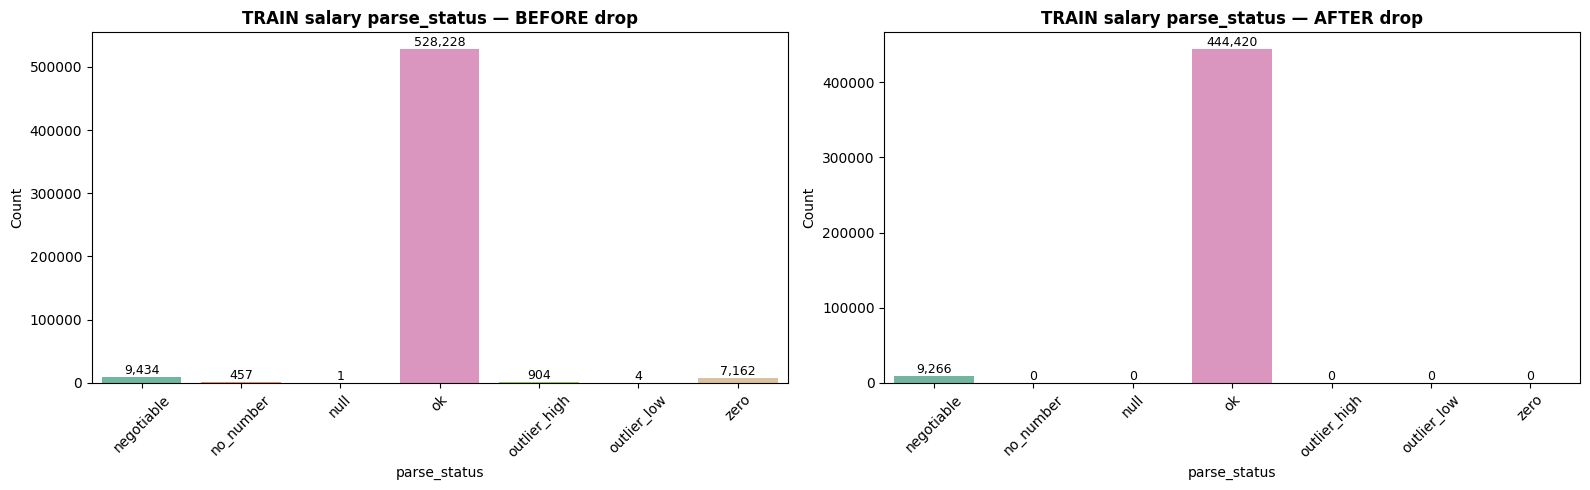

In [8]:
# Trực quan hóa parse_status TRAIN: trước vs sau khi clean_pipeline drop outliers
train_before = compute_parse_status(train_raw)
plot_parse_status(train_before, train_clean, title='TRAIN salary parse_status')

## 5. Clean test data

Load `raw_data_test.csv` → `clean_pipeline()` (cùng hàm với train, đảm bảo nhất quán) → save `clean_data_test.csv`.

In [9]:
%%time
test_raw = pd.read_parquet(RAW_TEST_PATH)
test_clean = clean_pipeline(test_raw, name='TEST')
print(f'\n✓ Cleaned TEST (in-memory): {test_clean.shape} — chưa save, đợi apply DOMAIN_STOPWORDS')

=== Cleaning TEST ===
Input: 60,688 rows × 14 cols
  [1] parse_salary: 96.68% ok  (salary_normalized = mean(min, max))
  [2] drop salary outliers: -975 rows → 59,713
  [3] clean_text: 5 cols normalized
  [4] drop duplicates: -1,511 rows → 58,202
  [5] drop desc < 20 tokens: -1,384 rows → 56,818
  [6] combined_text created
Output: 56,818 rows × 21 cols  (kept 93.62% of input)

✓ Cleaned TEST (in-memory): (56818, 21) — chưa save, đợi apply DOMAIN_STOPWORDS
CPU times: user 11.7 s, sys: 302 ms, total: 12 s
Wall time: 12 s


## 6. Phân tích top term frequency → DOMAIN_STOPWORDS

Sau khi clean với VI + EN, tokenize sample bằng `pyvi` rồi đếm **document frequency** (% docs chứa term). Term có DF > 30% → xuất hiện ở quá nhiều JD → không phân biệt được cluster → là stopword candidate.

Output: **`DOMAIN_STOPWORDS_AUTO`** (set tự động), dùng ở mục 7 để filter trước khi save.

Tokenize 50,000 JD với pyvi ...


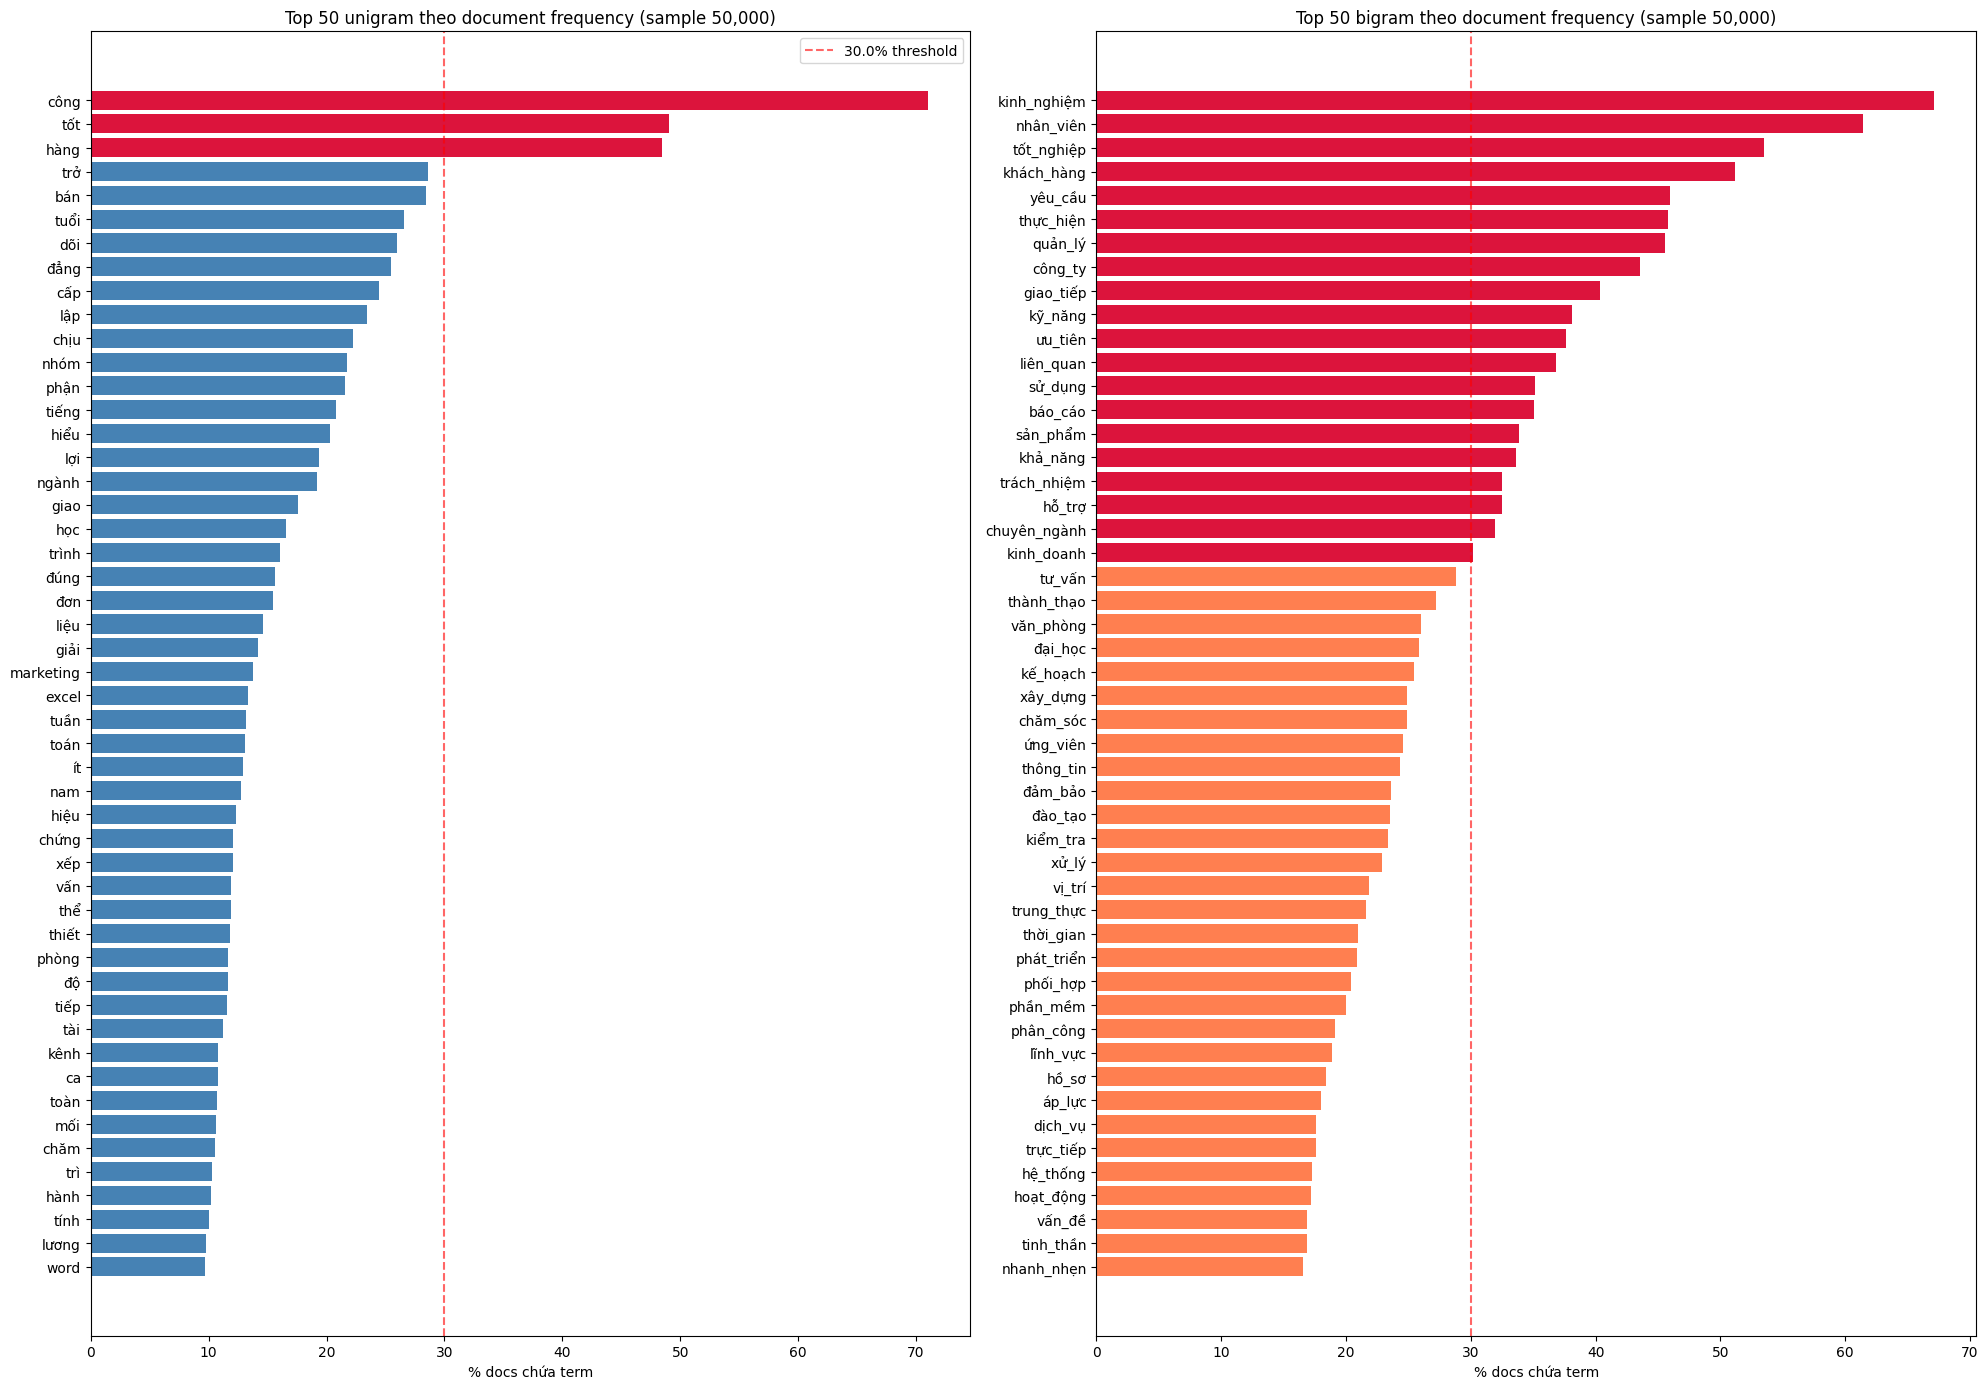


=== DOMAIN_STOPWORDS_AUTO (DF > 30.0%) ===
Tổng: 23 terms (3 unigram + 20 bigram)

        term  doc_freq_pct  is_bigram
        công        71.052      False
 kinh_nghiệm        67.130       True
   nhân_viên        61.396       True
  tốt_nghiệp        53.522       True
  khách_hàng        51.162       True
         tốt        49.014      False
        hàng        48.416      False
     yêu_cầu        45.942       True
   thực_hiện        45.834       True
     quản_lý        45.524       True
     công_ty        43.522       True
   giao_tiếp        40.380       True
     kỹ_năng        38.088       True
     ưu_tiên        37.598       True
   liên_quan        36.836       True
     sử_dụng        35.122       True
     báo_cáo        35.076       True
    sản_phẩm        33.832       True
    khả_năng        33.622       True
 trách_nhiệm        32.532       True
      hỗ_trợ        32.496       True
chuyên_ngành        31.896       True
  kinh_doanh        30.178       True
CPU 

In [10]:
%%time
import matplotlib.pyplot as plt
from collections import Counter
from pyvi import ViTokenizer

ANALYSIS_SAMPLE = 50_000
DF_THRESHOLD    = 30.0   # % document frequency để auto-pick là stopword

# Sample đã clean (in-memory train_clean)
df_sample = train_clean.sample(min(ANALYSIS_SAMPLE, len(train_clean)), random_state=42)
print(f'Tokenize {len(df_sample):,} JD với pyvi ...')

# Tokenize → unique tokens per doc
unique_tokens_per_doc = df_sample['combined_text'].apply(
    lambda t: set(ViTokenizer.tokenize(str(t)).split())
)

# Document frequency
doc_freq = Counter()
for tokens in unique_tokens_per_doc:
    doc_freq.update(tokens)
N = len(df_sample)

freq_df = pd.DataFrame([
    {'term': t, 'doc_freq_pct': c / N * 100, 'is_bigram': '_' in t}
    for t, c in doc_freq.items()
    if len(t) > 1 and not t.isdigit()
])

unigrams = freq_df[~freq_df['is_bigram']].sort_values('doc_freq_pct', ascending=False).head(50)
bigrams  = freq_df[ freq_df['is_bigram']].sort_values('doc_freq_pct', ascending=False).head(50)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(20, 14))
axes[0].barh(unigrams['term'][::-1], unigrams['doc_freq_pct'][::-1],
             color=['crimson' if v > DF_THRESHOLD else 'steelblue'
                    for v in unigrams['doc_freq_pct'][::-1]])
axes[0].axvline(DF_THRESHOLD, color='red', linestyle='--', alpha=0.6,
                label=f'{DF_THRESHOLD}% threshold')
axes[0].set_title(f'Top 50 unigram theo document frequency (sample {N:,})')
axes[0].set_xlabel('% docs chứa term'); axes[0].legend()

axes[1].barh(bigrams['term'][::-1], bigrams['doc_freq_pct'][::-1],
             color=['crimson' if v > DF_THRESHOLD else 'coral'
                    for v in bigrams['doc_freq_pct'][::-1]])
axes[1].axvline(DF_THRESHOLD, color='red', linestyle='--', alpha=0.6)
axes[1].set_title(f'Top 50 bigram theo document frequency (sample {N:,})')
axes[1].set_xlabel('% docs chứa term')

plt.tight_layout()
plt.savefig(OUT_TRAIN_PARQUET.parent / 'top_term_freq.png', dpi=120, bbox_inches='tight')
plt.show()

# Auto-extract DOMAIN_STOPWORDS từ DF threshold
candidates = freq_df[freq_df['doc_freq_pct'] > DF_THRESHOLD].sort_values('doc_freq_pct', ascending=False)
DOMAIN_STOPWORDS_AUTO = set(candidates['term'].tolist())

print(f'\n=== DOMAIN_STOPWORDS_AUTO (DF > {DF_THRESHOLD}%) ===')
print(f'Tổng: {len(DOMAIN_STOPWORDS_AUTO)} terms ({(~candidates["is_bigram"]).sum()} unigram + {candidates["is_bigram"].sum()} bigram)\n')
print(candidates[['term', 'doc_freq_pct', 'is_bigram']].to_string(index=False))

## 7. Apply `DOMAIN_STOPWORDS_AUTO` + Save

Mỗi term trong DOMAIN_STOPWORDS_AUTO ở dạng pyvi tokenized (vd `nhân_viên`) → chuyển về dạng untokenized (`nhân viên`) → regex word-boundary replace trên text columns của train_clean + test_clean → save final.

In [11]:
%%time
# Convert DOMAIN_STOPWORDS_AUTO ('a_b' tokenized) → ('a b' untokenized) regex patterns
domain_patterns = [
    re.compile(rf'\b{re.escape(sw.replace("_", " "))}\b', flags=re.IGNORECASE)
    for sw in DOMAIN_STOPWORDS_AUTO
]

def remove_domain_stopwords(text):
    if not isinstance(text, str) or not text:
        return text
    for pat in domain_patterns:
        text = pat.sub(' ', text)
    return re.sub(r'\s+', ' ', text).strip()

TEXT_COLS_FOR_DOMAIN = [
    'job_title', 'job_description', 'requirements',
    'benefits', 'company_name', 'combined_text',
]

# Apply to train_clean
print('Applying DOMAIN_STOPWORDS_AUTO to TRAIN...')
for col in TEXT_COLS_FOR_DOMAIN:
    if col in train_clean.columns:
        train_clean[col] = train_clean[col].apply(remove_domain_stopwords)

# Apply to test_clean
print('Applying DOMAIN_STOPWORDS_AUTO to TEST...')
for col in TEXT_COLS_FOR_DOMAIN:
    if col in test_clean.columns:
        test_clean[col] = test_clean[col].apply(remove_domain_stopwords)

# Update combined_len
if 'combined_len' in train_clean.columns:
    train_clean['combined_len'] = train_clean['combined_text'].str.split().str.len()
    test_clean['combined_len']  = test_clean['combined_text'].str.split().str.len()

# Save TRAIN
train_clean.to_parquet(OUT_TRAIN_PARQUET, compression='snappy', index=False)
train_clean.to_csv(OUT_TRAIN_CSV, index=False, encoding='utf-8')
print(f'\n✓ Saved TRAIN parquet → {OUT_TRAIN_PARQUET}  ({OUT_TRAIN_PARQUET.stat().st_size / 1024**2:.1f} MB)')
print(f'✓ Saved TRAIN CSV     → {OUT_TRAIN_CSV}  ({OUT_TRAIN_CSV.stat().st_size / 1024**2:.1f} MB)')

# Save TEST
test_clean.to_parquet(OUT_TEST_PARQUET, compression='snappy', index=False)
test_clean.to_csv(OUT_TEST_CSV, index=False, encoding='utf-8')
print(f'✓ Saved TEST  parquet → {OUT_TEST_PARQUET}  ({OUT_TEST_PARQUET.stat().st_size / 1024**2:.1f} MB)')
print(f'✓ Saved TEST  CSV     → {OUT_TEST_CSV}  ({OUT_TEST_CSV.stat().st_size / 1024**2:.1f} MB)')

Applying DOMAIN_STOPWORDS_AUTO to TRAIN...
Applying DOMAIN_STOPWORDS_AUTO to TEST...

✓ Saved TRAIN parquet → ../data/clean/clean_data_train.parquet  (395.2 MB)
✓ Saved TRAIN CSV     → ../data/clean/clean_data_train.csv  (935.1 MB)
✓ Saved TEST  parquet → ../data/clean/clean_data_test.parquet  (48.9 MB)
✓ Saved TEST  CSV     → ../data/clean/clean_data_test.csv  (116.9 MB)
CPU times: user 4min 39s, sys: 6.07 s, total: 4min 45s
Wall time: 4min 49s


## 8. Sanity check

Đọc lại 2 file CSV, verify shape + sample dòng để kiểm tra tiếng Việt vẫn đúng encoding sau khi đã apply DOMAIN_STOPWORDS_AUTO.

In [12]:
# Verify cả 2 format đọc lại OK
train_reload_pq = pd.read_parquet(OUT_TRAIN_PARQUET)
test_reload_pq  = pd.read_parquet(OUT_TEST_PARQUET)
train_reload_csv = pd.read_csv(OUT_TRAIN_CSV, encoding='utf-8')

print(f'Train parquet reload: {train_reload_pq.shape}')
print(f'Test  parquet reload: {test_reload_pq.shape}')
print(f'Train CSV reload    : {train_reload_csv.shape}')
assert train_reload_pq.shape == train_reload_csv.shape, 'Parquet và CSV phải cùng shape'

print('\nSample 3 dòng (kiểm tra tiếng Việt + combined_text):')
print(train_reload_pq[['job_title', 'combined_text']].head(3).to_string(index=False))

Train parquet reload: (453686, 21)
Test  parquet reload: (56818, 21)
Train CSV reload    : (453686, 21)

Sample 3 dòng (kiểm tra tiếng Việt + combined_text):
                                 job_title                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                